In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recommend import (load_catalogue, build_matrix, score_overlap,
                       score_tfidf, score_ppr, expected_rank, recommend)

pd.set_option("display.max_colwidth", 80)

In [2]:
cat = load_catalogue(min_reviews=5)
B, vocab, index = build_matrix(cat)
print(f"{B.shape[0]:,} recipes x {B.shape[1]:,} ingredients, {B.nnz:,} edges")

50,978 recipes x 6,580 ingredients, 450,958 edges


In [3]:
rng = np.random.default_rng(42)
sizes = np.diff(B.indptr)                     # ingredients per recipe
eligible = np.where(sizes >= 6)[0]
val_ids, test_ids = np.split(rng.choice(eligible, 1500, replace=False), [500])
print(len(eligible), "eligible recipes;", len(val_ids), "validation,", len(test_ids), "test")

def make_query(r, rng, keep=0.5):
    """Keep a random part of the recipe's ingredients: that is what the user 'has'."""
    ings = B[r].indices
    k = max(2, int(len(ings) * keep))
    return rng.choice(ings, size=k, replace=False)

def ppr_recipes(B, q, restart=0.3):
    return score_ppr(B, q, restart)[0]

def ranks_for(method, ids, keep=0.5, seed=0, **kw):
    rng = np.random.default_rng(seed)         # same seed -> same queries for every method
    ranks = []
    for r in ids:
        q = np.zeros(B.shape[1])
        q[make_query(r, rng, keep)] = 1
        ranks.append(expected_rank(method(B, q, **kw), r))
    return np.array(ranks)

def summary(ranks):
    return pd.Series({"hit@1": (ranks <= 1).mean(), "hit@10": (ranks <= 10).mean(),
                      "MRR": (1 / ranks).mean(), "median rank": np.median(ranks)})

41684 eligible recipes; 500 validation, 1000 test


In [4]:
tuning = pd.DataFrame({a: summary(ranks_for(ppr_recipes, val_ids, restart=a))
                       for a in [0.1, 0.3, 0.5, 0.7, 0.9]}).T
tuning.round(3)

,hit@1,hit@10,MRR,median rank
0.1,0.488,0.796,0.592,2.0
0.3,0.592,0.856,0.688,1.0
0.5,0.650,0.868,0.734,1.0
0.7,0.678,0.868,0.755,1.0
0.9,0.684,0.868,0.759,1.0


In [5]:
more = pd.DataFrame({a: summary(ranks_for(ppr_recipes, val_ids, restart=a))
                     for a in [0.95, 0.99]}).T
tuning = pd.concat([tuning, more])
tuning.round(3)

,hit@1,hit@10,MRR,median rank
0.10,0.488,0.796,0.592,2.0
0.30,0.592,0.856,0.688,1.0
0.50,0.650,0.868,0.734,1.0
0.70,0.678,0.868,0.755,1.0
0.90,0.684,0.868,0.759,1.0
0.95,0.684,0.868,0.759,1.0
0.99,0.684,0.868,0.759,1.0


In [6]:
best = tuning["MRR"].idxmax()
print("restart chosen on validation:", best)
ranks = {"overlap": ranks_for(score_overlap, test_ids),
         "tf-idf": ranks_for(score_tfidf, test_ids),
         "ppr": ranks_for(ppr_recipes, test_ids, restart=best)}
results = pd.DataFrame({m: summary(r) for m, r in ranks.items()}).T
results.round(3).to_csv("../results/recommender_results.csv")
results.round(3)

restart chosen on validation: 0.99


,hit@1,hit@10,MRR,median rank
overlap,0.652,0.904,0.766,1.0
tf-idf,0.609,0.866,0.697,1.0
ppr,0.694,0.879,0.762,1.0


In [12]:
def bootstrap_ci(a, b, metric, n=1000, seed=1):
    """95% interval of metric(a) - metric(b), resampling the same test recipes for both."""
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n):
        s = rng.integers(0, len(a), len(a))
        diffs.append(metric(a[s]) - metric(b[s]))
    return np.percentile(diffs, [2.5, 97.5]).round(3)

def hit10(r):
    return (r <= 10).mean()

def mrr(r):
    return (1 / r).mean()
    
def hit1(r):
    return (r <= 1).mean()

for base in ["overlap", "tf-idf"]:
    print(f"ppr - {base}:  hit@1 {bootstrap_ci(ranks['ppr'], ranks[base], hit1)}"
          f"  hit@10 {bootstrap_ci(ranks['ppr'], ranks[base], hit10)}"
          f"  MRR {bootstrap_ci(ranks['ppr'], ranks[base], mrr)}")

ppr - overlap:  hit@1 [0.031 0.054]  hit@10 [-0.036 -0.016]  MRR [-0.011  0.002]
ppr - tf-idf:  hit@1 [0.055 0.114]  hit@10 [-0.008  0.033]  MRR [0.044 0.086]


In [13]:
freq = np.asarray(B.sum(axis=0)).ravel()
p_fridge = freq / freq.sum()          # extra items drawn like a real fridge: common ones more often

def fridge_query(r, rng, keep=0.5, extra=3):
    """Half of the recipe's ingredients + `extra` ingredients the recipe does not use."""
    ings = B[r].indices
    k = max(2, int(len(ings) * keep))
    have = list(rng.choice(ings, size=k, replace=False))
    while len(have) < k + extra:
        i = rng.choice(len(p_fridge), p=p_fridge)
        if i not in ings and i not in have:
            have.append(i)
    return np.array(have)

def ranks_fridge(method, ids, extra=3, seed=0, **kw):
    rng = np.random.default_rng(seed)
    ranks = []
    for r in ids:
        q = np.zeros(B.shape[1])
        q[fridge_query(r, rng, extra=extra)] = 1
        ranks.append(expected_rank(method(B, q, **kw), r))
    return np.array(ranks)

In [14]:
pd.DataFrame({a: summary(ranks_fridge(ppr_recipes, val_ids, restart=a))
              for a in [0.3, 0.5, 0.7, 0.9, 0.99]}).T.round(3)

,hit@1,hit@10,MRR,median rank
0.30,0.374,0.576,0.446,4.75
0.50,0.394,0.586,0.466,3.00
0.70,0.418,0.592,0.483,3.00
0.90,0.430,0.592,0.491,3.00
0.99,0.430,0.592,0.491,3.00


,overlap,tf-idf,ppr
extra ingredients,,,
0,0.766,0.697,0.762
2,0.597,0.637,0.587
4,0.463,0.581,0.443
6,0.337,0.528,0.377


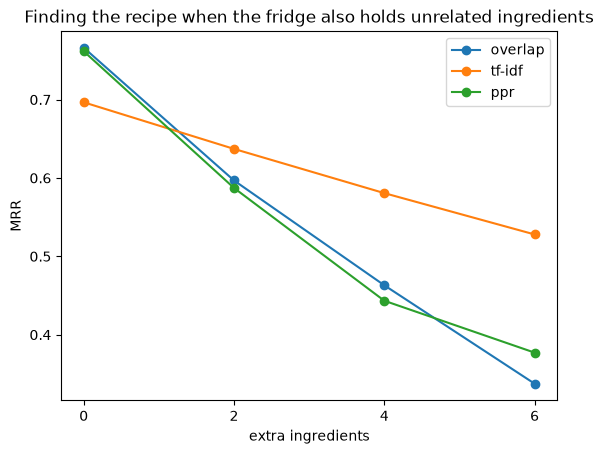

In [16]:
mrr_by_noise = {}
for extra in [0, 2, 4, 6]:
    rk = {"overlap": ranks_fridge(score_overlap, test_ids, extra),
          "tf-idf": ranks_fridge(score_tfidf, test_ids, extra),
          "ppr": ranks_fridge(ppr_recipes, test_ids, extra, restart=best)}
    mrr_by_noise[extra] = {m: (1 / r).mean() for m, r in rk.items()}
noise = pd.DataFrame(mrr_by_noise).T
noise.index.name = "extra ingredients"
noise.round(3).to_csv("../results/recommender_noise.csv")
noise.plot(marker="o")
plt.ylabel("MRR")
plt.title("Finding the recipe when the fridge also holds unrelated ingredients")
plt.xticks([0, 2, 4, 6])
plt.savefig("../figures/recommender_noise.png", dpi=200, bbox_inches="tight")
noise.round(3)

In [17]:
import networkx as nx
from config import MIN_RECIPES, MIN_COOC, MIN_NPMI, SEED
from graph import build_ingredient_graph

fc_recipes = [{"ingredients": list(ings)} for ings in cat["ingredients"]]
Gf = build_ingredient_graph(fc_recipes, MIN_RECIPES, MIN_COOC, MIN_NPMI)
Hf = Gf.subgraph(max(nx.connected_components(Gf), key=len))
comms_f = sorted(nx.community.louvain_communities(Hf, weight="npmi", seed=SEED), key=len, reverse=True)
community = {n: k for k, c in enumerate(comms_f) for n in c}
for n in Gf:
    Gf.nodes[n]["community"] = community.get(n, -1)
print(Gf)
print(len(comms_f), "communities, modularity",
      round(nx.community.modularity(Hf, comms_f, weight="npmi"), 3))
for k, c in enumerate(comms_f):
    top = sorted(c, key=lambda n: -Gf.nodes[n]["recipes"])[:8]
    print(k, len(c), top)
nx.write_graphml(Gf, "../results/foodcom_ingredient_graph.graphml")

Graph with 1547 nodes and 12265 edges
7 communities, modularity 0.5
0 322 ['salt', 'butter', 'egg', 'sugar', 'milk', 'flour', 'brown sugar', 'baking powder']
1 303 ['onion', 'water', 'pepper', 'parmesan cheese', 'salt and pepper', 'carrot', 'chicken broth', 'celery']
2 238 ['olive oil', 'garlic clove', 'lemon juice', 'fresh parsley', 'fresh ground black pepper', 'red onion', 'dijon mustard', 'fresh lemon juice']
3 174 ['garlic', 'scallion', 'vegetable oil', 'soy sauce', 'oil', 'chicken breast', 'honey', 'cornstarch']
4 139 ['black pepper', 'garlic powder', 'mayonnaise', 'paprika', 'worcestershire sauce', 'cayenne pepper', 'bacon', 'ketchup']
5 126 ['cheddar', 'sour cream', 'tomato', 'chili powder', 'ground cumin', 'tortilla', 'cumin', 'lettuce']
6 38 ['orange juice', 'rum', 'ice cube', 'ice', 'whipped cream', 'pineapple juice', 'vodka', 'orange']
